<a href="https://colab.research.google.com/github/Hassanat718/Module-3-case-Exercise/blob/main/Case_Exercise_3_Metocean_Fatigue_Correlation_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Case Exercise 3: Metocean-Fatigue Correlation Model**

##**Project Overview**

This notebook develops a spectral fatigue assessment pipeline using the Jubilee TRP3 metocean dataset.

The workflow will:

1. Generate wave energy spectra using the JONSWAP spectrum.
2. Convert wave spectra into stress response spectra using a simplified transfer function.
3. Calculate hourly fatigue damage using the narrow-band spectral fatigue method.
4. Build a metocean-fatigue correlation dataset.
5. Develop polynomial regression models to predict fatigue damage.
6. Evaluate model performance using cross-validation and residual analysis.
7. Visualise fatigue damage trends and model predictions.

## 2. Important Methodological Note

The simplified transfer function is an approximation for this training exercise. It is not a substitute for detailed hydrodynamic and structural response analysis using OrcaFlex.

The calculated fatigue damage will therefore be treated as modelled or synthetic fatigue damage, not measured riser fatigue performance.


In [51]:
# Import libraries for data analysis, numerical calculations and visualisation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import mathematical functions
import math
from scipy.special import gamma as gamma_fn

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# Set visualisation style
sns.set_style('whitegrid')

print("Libraries imported successfully.")


Libraries imported successfully.



## **Loading the Metocean Dataset**

The Jubilee TRP3 dataset contains hourly metocean observations for 2025.

The dataset provides the environmental conditions required for the fatigue assessment, including:

- Significant wave height (Hs)
- Peak wave period (Tp)
- Current speed (Uc)
- Wind speed (U10)
- Other environmental variables

Each hourly observation will be used to estimate the corresponding fatigue damage.


In [4]:

# Import the Google Colab file upload utility
from google.colab import files

# Open the file selection window
uploaded = files.upload()


Saving Jubilee_TRP3_Metocean.csv to Jubilee_TRP3_Metocean.csv


# **Load the uploaded dataset**

In [5]:
# Load the uploaded CSV file
df = pd.read_csv("Jubilee_TRP3_Metocean.csv")

# Display the first five rows
df.head()


,timestamp,Hs,season,Tp,MWD,Uc,CD,U10,SST,d
0,2025-01-01 00:00:00,1.5249,Dry,14.5806,202.4724,0.6532,236.7441,4.3755,24.4974,838
1,2025-01-01 01:00:00,1.2600,Dry,14.2787,237.0429,0.4710,295.7411,6.4522,29.5140,838
2,2025-01-01 02:00:00,1.2600,Dry,13.9385,223.9196,0.5760,285.2917,5.0083,25.7720,838
3,2025-01-01 03:00:00,1.4542,Dry,14.1379,215.9195,0.5640,281.5023,3.9326,28.4737,838
4,2025-01-01 04:00:00,1.3384,Dry,13.6802,189.3611,0.6396,31.9095,4.3208,29.3088,838


# **Inspect the dataset**

In [6]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (8760, 10)

Column names:
['timestamp', 'Hs', 'season', 'Tp', 'MWD', 'Uc', 'CD', 'U10', 'SST', 'd']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  8760 non-null   object 
 1   Hs         8760 non-null   float64
 2   season     8760 non-null   object 
 3   Tp         8760 non-null   float64
 4   MWD        8760 non-null   float64
 5   Uc         8760 non-null   float64
 6   CD         8760 non-null   float64
 7   U10        8760 non-null   float64
 8   SST        8760 non-null   float64
 9   d          8760 non-null   int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 684.5+ KB

Missing values:
timestamp    0
Hs           0
season       0
Tp           0
MWD          0
Uc           0
CD           0
U10          0
SST          0
d            0
dtype: int64

Duplicate rows: 0


# **Convert timestamp to datetime**

In [7]:
# Convert timestamp column into datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Sort observations chronologically
df = df.sort_values('timestamp').reset_index(drop=True)

# Display the first and last timestamps
print("Start:", df['timestamp'].min())
print("End:", df['timestamp'].max())

# Display total number of observations
print("Total observations:", len(df))


Start: 2025-01-01 00:00:00
End: 2025-12-31 23:00:00
Total observations: 8760



### **Metocean Data Preparation**

The spectral fatigue pipeline requires four main environmental variables:

- Hs: Significant wave height (m)
- Tp: Peak wave period (s)
- Uc: Current speed (m/s)
- U10: Wind speed (m/s)

We will retain the original dataset and create a separate working DataFrame containing the variables required for fatigue modelling.


In [8]:
# Select the variables required for fatigue modelling
metocean_df = df[
    ['timestamp', 'Hs', 'Tp', 'Uc', 'U10']
].copy()

# Rename columns to match the Section 3.6 function
metocean_df = metocean_df.rename(columns={
    'Hs': 'hs_m',
    'Tp': 'tp_s',
    'Uc': 'current_ms',
    'U10': 'wind_ms'
})

# Display the first five observations
metocean_df.head()


,timestamp,hs_m,tp_s,current_ms,wind_ms
0,2025-01-01 00:00:00,1.5249,14.5806,0.6532,4.3755
1,2025-01-01 01:00:00,1.2600,14.2787,0.4710,6.4522
2,2025-01-01 02:00:00,1.2600,13.9385,0.5760,5.0083
3,2025-01-01 03:00:00,1.4542,14.1379,0.5640,3.9326
4,2025-01-01 04:00:00,1.3384,13.6802,0.6396,4.3208


In [9]:
# Generate descriptive statistics
metocean_df.describe()

,timestamp,hs_m,tp_s,current_ms,wind_ms
count,8760,8760.0000,8760.0000,8760.0000,8760.0000
mean,2025-07-02 11:30:00,1.6543,11.3295,0.7274,5.7672
min,2025-01-01 00:00:00,1.2600,8.0000,0.3000,0.5534
25%,2025-04-02 05:45:00,1.3843,9.5726,0.5618,3.9391
50%,2025-07-02 11:30:00,1.6409,11.0032,0.7100,5.4904
75%,2025-10-01 17:15:00,1.8867,13.2095,0.8837,7.5040
max,2025-12-31 23:00:00,2.7138,16.2000,1.4672,13.2035
std,NaN,0.2959,2.0993,0.2141,2.2346



### **JONSWAP Wave Energy Spectrum**

The JONSWAP (Joint North Sea Wave Project) spectrum describes how wave energy is distributed across different wave frequencies.

The function uses:

- Significant wave height (Hs)
- Peak wave period (Tp)
- Frequency array
- Peak enhancement factor (gamma)

The resulting wave spectrum will be used as the input to the simplified stress transfer function.

For this exercise, gamma = 2.5, following the supplied Section 3.6 guidance.


In [11]:

def jonswap_spectrum(
    hs: float,
    tp: float,
    frequencies: np.ndarray,
    gamma: float = 2.5
) -> np.ndarray:

    """
    Generate the JONSWAP wave energy spectrum.

    Parameters:
        hs: Significant wave height (m)
        tp: Peak wave period (s)
        frequencies: Frequency array (Hz)
        gamma: Peak enhancement factor

    Returns:
        Wave spectral density
    """

    # Check that inputs are physically valid
    if hs <= 0 or tp <= 0:
        raise ValueError("Hs and Tp must be positive.")

    if np.any(frequencies <= 0) or np.any(np.diff(frequencies) <= 0):
        raise ValueError("Frequencies must be positive and increasing.")

    # Calculate peak frequency
    fp = 1.0 / tp

    # Physical constants
    alpha = 0.0081
    g = 9.81

    # Calculate Pierson-Moskowitz base spectrum
    pm = (
        alpha * g**2 / (2 * np.pi)**4
        * frequencies**(-5)
        * np.exp(-1.25 * (fp / frequencies)**4)
    )

    # Calculate JONSWAP peak enhancement
    sigma = np.where(frequencies <= fp, 0.07, 0.09)

    peak_factor = gamma ** np.exp(
        -0.5 * ((frequencies - fp) / (sigma * fp))**2
    )

    # Combine the base spectrum and peak enhancement
    S = pm * peak_factor

    # Calculate the zeroth spectral moment
    m0 = np.trapezoid(S, frequencies)

    # Calculate the significant wave height represented by the spectrum
    hs_actual = 4 * np.sqrt(m0)

    # Scale the spectrum to match the input significant wave height
    S *= (hs / hs_actual)**2

    return S



## **Testing the JONSWAP Spectrum**

We will use the first hourly observation in the Jubilee TRP3 dataset to generate a wave energy spectrum.

The frequency range will be 0.02–0.5 Hz, divided into 200 frequency points.

We will then verify that the generated spectrum reproduces the input significant wave height using:

Hs = 4 × √m0

where m0 is the zeroth spectral moment.


# **Generate the frequency array**

In [12]:
# Generate 200 frequencies between 0.02 Hz and 0.5 Hz
freqs = np.linspace(0.02, 0.5, 200)

# Display the first and last five frequency values
print("Frequency range:", freqs.min(), "to", freqs.max(), "Hz")
print("Number of frequency points:", len(freqs))


Frequency range: 0.02 to 0.5 Hz
Number of frequency points: 200


# **Generate the spectrum**

In [13]:

# Select the first hourly observation
sample = metocean_df.iloc[0]

# Generate its JONSWAP wave spectrum
wave_S = jonswap_spectrum(
    hs=sample['hs_m'],
    tp=sample['tp_s'],
    frequencies=freqs,
    gamma=2.5
)

# Display the input conditions and spectrum information
print("Significant wave height:", sample['hs_m'], "m")
print("Peak wave period:", sample['tp_s'], "s")
print("Spectrum array shape:", wave_S.shape)
print("Minimum spectral density:", wave_S.min())
print("Maximum spectral density:", wave_S.max())


Significant wave height: 1.5248542243810248 m
Peak wave period: 14.580621208954168 s
Spectrum array shape: (200,)
Minimum spectral density: 3.1480334605951474e-72
Maximum spectral density: 5.5805478203844165


# **Verify the significant wave height**

In [14]:
# Calculate the zeroth spectral moment
m0 = np.trapezoid(wave_S, freqs)

# Reconstruct significant wave height
hs_reconstructed = 4 * np.sqrt(m0)

print("Original Hs:", sample['hs_m'], "m")
print("Reconstructed Hs:", hs_reconstructed, "m")


Original Hs: 1.5248542243810248 m
Reconstructed Hs: 1.524854224381025 m



## **Visualisation of the JONSWAP Wave Spectrum**

We will plot spectral density against wave frequency.

The peak of the spectrum represents the frequency around which the greatest wave energy is concentrated.

The peak frequency is related to the peak wave period by:

fp = 1 / Tp


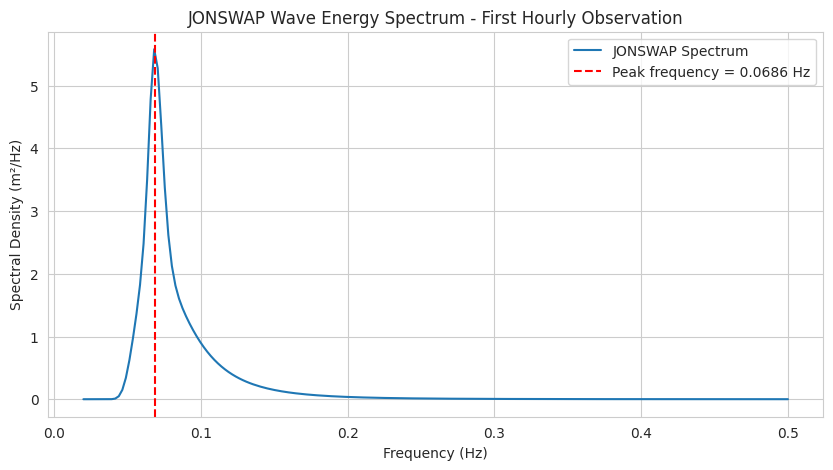

In [15]:
# Calculate the peak frequency
fp = 1 / sample['tp_s']

# Plot the wave energy spectrum
plt.figure(figsize=(10, 5))

plt.plot(freqs, wave_S, label='JONSWAP Spectrum')

# Mark the peak frequency
plt.axvline(
    fp,
    color='red',
    linestyle='--',
    label=f'Peak frequency = {fp:.4f} Hz'
)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Spectral Density (m²/Hz)')
plt.title('JONSWAP Wave Energy Spectrum - First Hourly Observation')

plt.legend()
plt.grid(True)
plt.show()



## **Simplified Wave-to-Stress Transfer Function**

A simplified frequency-dependent transfer function is developed to convert the JONSWAP wave spectrum into a stress response spectrum.

The proposed function is:

TF(f, Uc) = K / sqrt(1 + (f/fc)^4) × (1 + βUc)

Assumed parameters:

- K = 100: Baseline transfer coefficient
- fc = 0.10 Hz: Characteristic response frequency
- β = 0.20: Current sensitivity coefficient

These parameters are illustrative assumptions for the training exercise. They are not derived from OrcaFlex simulations, measured riser stresses, or structural calibration data.

The resulting fatigue estimates are therefore synthetic and suitable for demonstrating the modelling workflow, not for engineering design or operational integrity decisions.


In [16]:

def simplified_transfer_function(
    frequencies: np.ndarray,
    current_ms: float,
    K: float = 100.0,
    fc: float = 0.10,
    beta: float = 0.20
) -> np.ndarray:

    """
    Calculate an illustrative frequency-dependent
    wave-to-stress transfer function.

    Parameters:
        frequencies: Frequency array (Hz)
        current_ms: Current speed (m/s)
        K: Baseline transfer coefficient
        fc: Characteristic response frequency (Hz)
        beta: Current sensitivity coefficient

    Returns:
        Transfer function values
    """

    # Validate inputs
    if np.any(frequencies <= 0):
        raise ValueError("Frequencies must be positive.")

    if current_ms < 0 or K <= 0 or fc <= 0:
        raise ValueError("Current speed, K and fc must be valid.")

    # Calculate frequency-dependent response
    frequency_response = 1 / np.sqrt(
        1 + (frequencies / fc)**4
    )

    # Calculate current-speed adjustment
    current_adjustment = 1 + beta * current_ms

    # Combine both components
    tf = K * frequency_response * current_adjustment

    return tf


# **Test the function**

In [17]:
# Calculate the transfer function for the first observation
tf = simplified_transfer_function(
    frequencies=freqs,
    current_ms=sample['current_ms']
)

# Display basic information
print("Transfer function shape:", tf.shape)
print("Minimum TF:", tf.min())
print("Maximum TF:", tf.max())
print("Current speed:", sample['current_ms'], "m/s")


Transfer function shape: (200,)
Minimum TF: 4.518960752713336
Maximum TF: 112.97401881783338
Current speed: 0.6532180955047056 m/s



## **Generating the Stress Response Spectrum**

The wave spectrum is transformed into a stress response spectrum using the simplified transfer function.

The relationship is:

S_stress(f) = S_wave(f) × TF(f)²

The squared transfer function represents the transformation of the spectral density through the linear response model.

The resulting stress spectrum will be used to calculate spectral moments and hourly fatigue damage.


In [18]:
# Apply the squared transfer function to the wave spectrum
stress_S = wave_S * tf**2

# Display stress spectrum information
print("Stress spectrum shape:", stress_S.shape)
print("Minimum stress spectral density:", stress_S.min())
print("Maximum stress spectral density:", stress_S.max())

# Check that all values are non-negative
print("All values non-negative:", np.all(stress_S >= 0))


Stress spectrum shape: (200,)
Minimum stress spectral density: 4.01787569267685e-68
Maximum stress spectral density: 58625.47656588435
All values non-negative: True


# **Visualise both spectra**

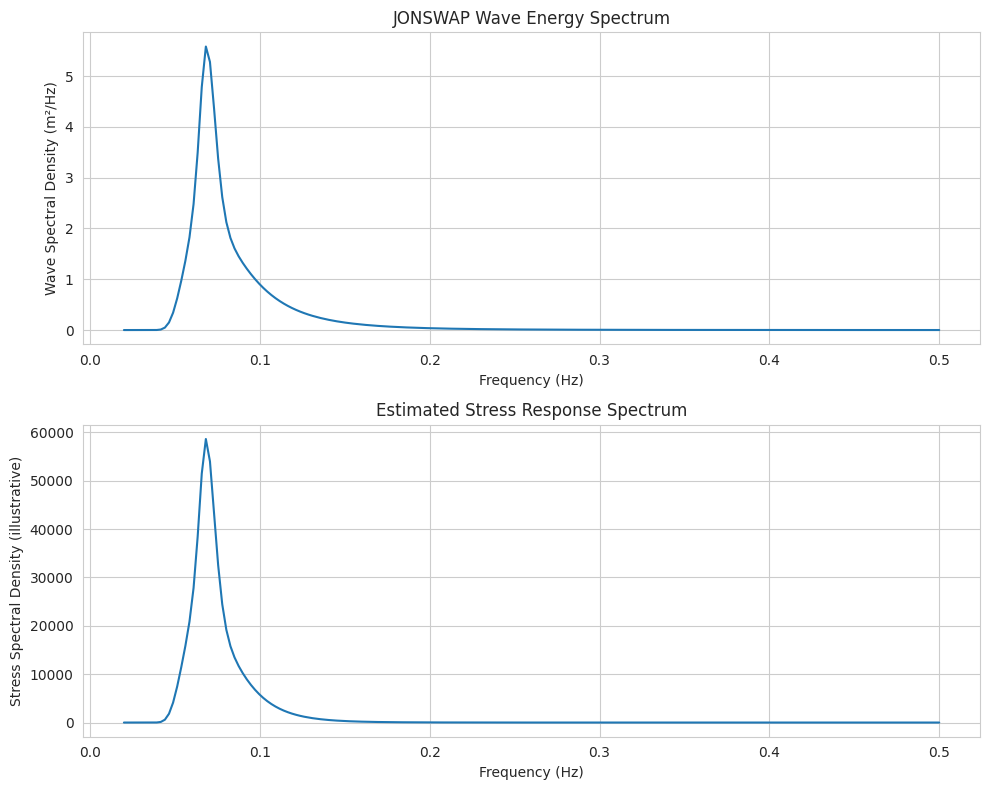

In [19]:
# Plot wave and stress response spectra
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Wave energy spectrum
axes[0].plot(freqs, wave_S)
axes[0].set_title("JONSWAP Wave Energy Spectrum")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Wave Spectral Density (m²/Hz)")
axes[0].grid(True)

# Stress response spectrum
axes[1].plot(freqs, stress_S)
axes[1].set_title("Estimated Stress Response Spectrum")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Stress Spectral Density (illustrative)")
axes[1].grid(True)

plt.tight_layout()
plt.show()



## **Spectral Fatigue Damage Calculation**

Fatigue damage is estimated using the narrow-band spectral fatigue method.

The calculation follows these steps:

1. Calculate spectral moments m0, m2 and m4.
2. Calculate the zero-crossing frequency.
3. Estimate the number of stress cycles in one hour.
4. Calculate RMS stress.
5. Apply the S-N curve parameters and Rayleigh narrow-band approximation.

The S-N curve parameters supplied for this exercise are:

- log10(A) = 11.764
- m = 3.0

The calculation assumes a one-hour duration for each observation.


In [20]:

def spectral_fatigue_damage(
    stress_spectrum: np.ndarray,
    frequencies: np.ndarray,
    sn_log_a: float = 11.764,
    sn_m: float = 3.0,
    duration_hours: float = 1.0
) -> float:

    """
    Calculate fatigue damage from a stress response spectrum.

    Uses the narrow-band approximation with Rayleigh
    distribution of stress peaks.

    Parameters:
        stress_spectrum: Stress response spectral density
        frequencies: Frequency array (Hz)
        sn_log_a: Log10 of S-N curve intercept A
        sn_m: S-N curve slope
        duration_hours: Duration of exposure in hours

    Returns:
        Estimated fatigue damage
    """

    # Calculate spectral moments
    m0 = np.trapezoid(stress_spectrum, frequencies)

    m2 = np.trapezoid(
        stress_spectrum * frequencies**2,
        frequencies
    )

    m4 = np.trapezoid(
        stress_spectrum * frequencies**4,
        frequencies
    )

    # Validate spectral moments
    if m0 <= 0 or m2 <= 0:
        raise ValueError("Spectral moments m0 and m2 must be positive.")

    # Calculate zero-crossing frequency
    f0 = math.sqrt(m2 / m0)

    # Calculate number of cycles in the exposure duration
    n_cycles = f0 * duration_hours * 3600

    # Convert S-N intercept from logarithmic to linear scale
    a = 10**sn_log_a

    # Calculate RMS stress
    sigma_s = math.sqrt(m0)

    # Calculate narrow-band fatigue damage
    damage = (
        n_cycles / a
        * (2 * math.sqrt(2) * sigma_s)**sn_m
        * gamma_fn(1 + sn_m / 2)
    )

    return damage


# **Calculate damage for the first hour**

In [21]:
# Calculate fatigue damage for the first hourly observation
hourly_damage = spectral_fatigue_damage(
    stress_spectrum=stress_S,
    frequencies=freqs,
    sn_log_a=11.764,
    sn_m=3.0,
    duration_hours=1.0
)

# Display the estimated hourly fatigue damage
print("Hourly fatigue damage:", hourly_damage)


Hourly fatigue damage: 0.000654585337955344



## **Building the Metocean-Fatigue Correlation Dataset**

The spectral fatigue calculation will now be applied to all 8,760 hourly observations.

For each observation, the workflow will:

1. Generate a JONSWAP wave spectrum using Hs and Tp.
2. Calculate the transfer function using frequency and current speed.
3. Generate the stress response spectrum.
4. Calculate hourly fatigue damage.
5. Store the metocean conditions and corresponding damage.

The resulting dataset will contain paired environmental conditions and estimated hourly fatigue damage.

Note: Wind speed will be retained as a potential ML predictor, but it does not currently influence the simplified transfer function or the calculated damage.


In [22]:
def build_fatigue_correlation_dataset(
    metocean_df: pd.DataFrame,
    transfer_function: callable,
    sn_params: dict
) -> pd.DataFrame:

    """
    Build a dataset pairing hourly metocean conditions
    with estimated spectral fatigue damage.
    """

    results = []

    # Generate the frequency array
    freqs = np.linspace(0.02, 0.5, 200)

    # Process each hourly observation
    for _, row in metocean_df.iterrows():

        # Generate JONSWAP wave spectrum
        wave_S = jonswap_spectrum(
            hs=row['hs_m'],
            tp=row['tp_s'],
            frequencies=freqs,
            gamma=2.5
        )

        # Calculate the wave-to-stress transfer function
        tf = transfer_function(
            frequencies=freqs,
            current_ms=row['current_ms']
        )

        # Generate stress response spectrum
        stress_S = wave_S * tf**2

        # Calculate hourly fatigue damage
        damage = spectral_fatigue_damage(
            stress_spectrum=stress_S,
            frequencies=freqs,
            sn_log_a=sn_params['log_a'],
            sn_m=sn_params['m'],
            duration_hours=1.0
        )

        # Store metocean conditions and estimated damage
        results.append({
            'timestamp': row['timestamp'],
            'hs_m': row['hs_m'],
            'tp_s': row['tp_s'],
            'current_ms': row['current_ms'],
            'wind_ms': row['wind_ms'],
            'hourly_damage': damage
        })

    return pd.DataFrame(results)


# **Run the full-year calculation**

In [23]:

# Define the S-N curve parameters
sn_params = {
    'log_a': 11.764,
    'm': 3.0
}

# Build the full-year fatigue correlation dataset
fatigue_df = build_fatigue_correlation_dataset(
    metocean_df=metocean_df,
    transfer_function=simplified_transfer_function,
    sn_params=sn_params
)

# Display the first five records
fatigue_df.head()


,timestamp,hs_m,tp_s,current_ms,wind_ms,hourly_damage
0,2025-01-01 00:00:00,1.5249,14.5806,0.6532,4.3755,0.0007
1,2025-01-01 01:00:00,1.2600,14.2787,0.4710,6.4522,0.0003
2,2025-01-01 02:00:00,1.2600,13.9385,0.5760,5.0083,0.0003
3,2025-01-01 03:00:00,1.4542,14.1379,0.5640,3.9326,0.0005
4,2025-01-01 04:00:00,1.3384,13.6802,0.6396,4.3208,0.0004


In [24]:
# Check the dimensions of the generated dataset
print("Dataset shape:", fatigue_df.shape)

# Check for missing values
print("\nMissing values:")
print(fatigue_df.isnull().sum())

# Check the fatigue damage statistics
print("\nHourly fatigue damage statistics:")
print(fatigue_df['hourly_damage'].describe())

# Check whether all damage values are non-negative
print(
    "\nAll damage values non-negative:",
    (fatigue_df['hourly_damage'] >= 0).all()
)


Dataset shape: (8760, 6)

Missing values:
timestamp        0
hs_m             0
tp_s             0
current_ms       0
wind_ms          0
hourly_damage    0
dtype: int64

Hourly fatigue damage statistics:
count   8760.0000
mean       0.0006
std        0.0003
min        0.0001
25%        0.0004
50%        0.0005
75%        0.0008
max        0.0034
Name: hourly_damage, dtype: float64

All damage values non-negative: True



## **Exploratory Analysis of Metocean-Fatigue Relationships**

This section investigates the relationships between environmental conditions and estimated hourly fatigue damage.

We will:

1. Calculate correlations between metocean variables and fatigue damage.
2. Visualise significant relationships using scatter plots.
3. Identify which environmental variables appear most influential.

This analysis will help us understand the dataset before developing polynomial regression models.


In [26]:
# Select numerical variables for correlation analysis
correlation_columns = [
    'hs_m',
    'tp_s',
    'current_ms',
    'wind_ms',
    'hourly_damage'
]

# Calculate the Pearson correlation matrix
correlation_matrix = fatigue_df[correlation_columns].corr()

# Display correlations with hourly fatigue damage
print("Correlation with hourly fatigue damage:")
print(
    correlation_matrix['hourly_damage']
    .sort_values(ascending=False)
)

Correlation with hourly fatigue damage:
hourly_damage    1.0000
hs_m             0.8165
current_ms       0.4591
wind_ms          0.3650
tp_s            -0.2067
Name: hourly_damage, dtype: float64


# **Visualise the relationships**

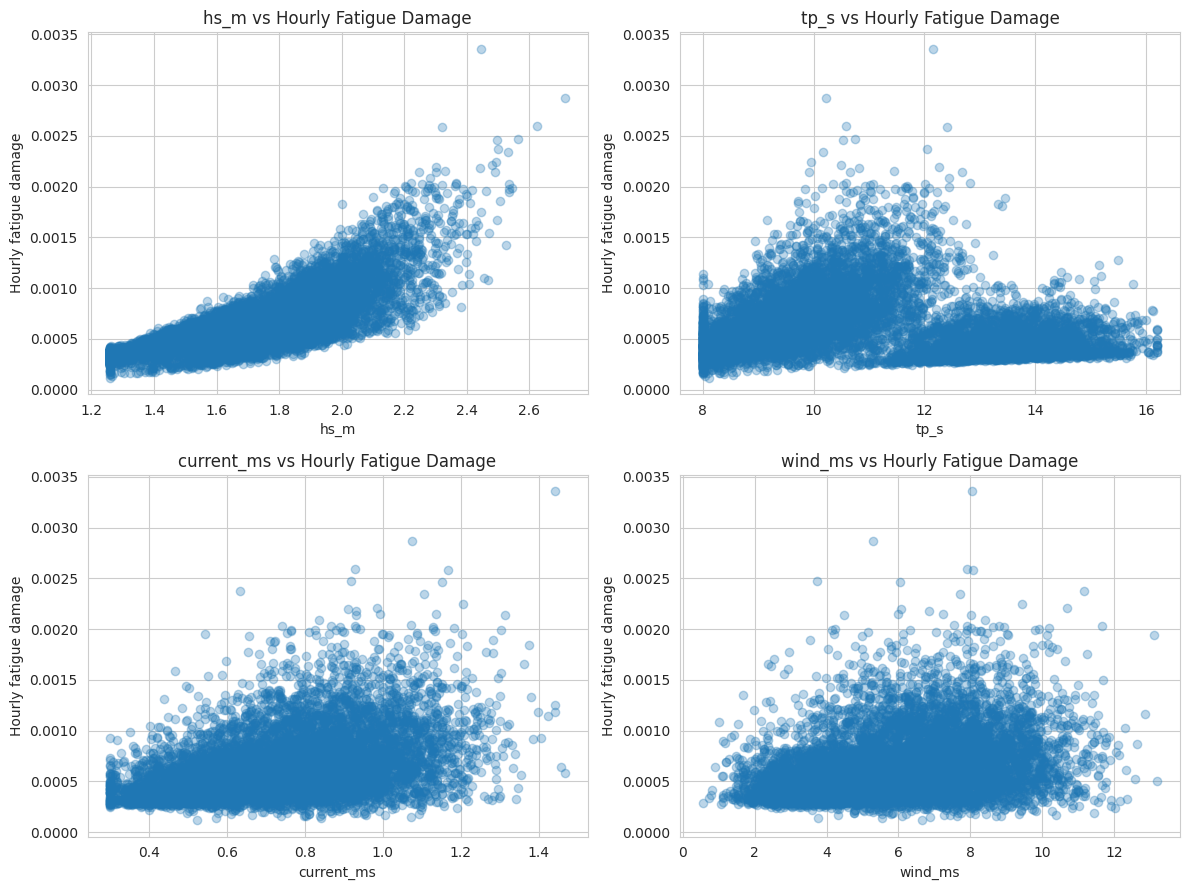

In [27]:
# Define the environmental variables
features = ['hs_m', 'tp_s', 'current_ms', 'wind_ms']

# Create scatter plots against hourly fatigue damage
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features):

    # Plot each environmental variable against fatigue damage
    ax.scatter(
        fatigue_df[feature],
        fatigue_df['hourly_damage'],
        alpha=0.3
    )

    ax.set_xlabel(feature)
    ax.set_ylabel('Hourly fatigue damage')
    ax.set_title(f'{feature} vs Hourly Fatigue Damage')
    ax.grid(True)

plt.tight_layout()
plt.show()



## **Polynomial Regression Model Preparation**

Polynomial regression will be used to model the relationship between metocean conditions and estimated hourly fatigue damage.

The target variable is hourly_damage.

The predictor variables are:

- hs_m: Significant wave height
- tp_s: Peak wave period
- current_ms: Current speed
- wind_ms: Wind speed

We will compare polynomial models of degrees 1, 2 and 3.

The data will be split into training and testing subsets. A chronological split will be used to preserve the time ordering of the observations and provide a more realistic test of predictions on later observations.


In [28]:
# Select predictor variables
X = fatigue_df[
    ['hs_m', 'tp_s', 'current_ms', 'wind_ms']
]

# Select the target variable
y = fatigue_df['hourly_damage']

# Check the dimensions
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Display the first five predictor observations
X.head()


Feature shape: (8760, 4)
Target shape: (8760,)


,hs_m,tp_s,current_ms,wind_ms
0,1.5249,14.5806,0.6532,4.3755
1,1.2600,14.2787,0.4710,6.4522
2,1.2600,13.9385,0.5760,5.0083
3,1.4542,14.1379,0.5640,3.9326
4,1.3384,13.6802,0.6396,4.3208


# **Split the data chronologically**

In [29]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Split without shuffling to preserve chronological order
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

# Display the training and testing dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))


Training features: (7008, 4)
Testing features: (1752, 4)
Training observations: 7008
Testing observations: 1752


# **Scale the predictor variables**

In [30]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform training predictors
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing predictors using the training scaler
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)


Training data scaled: (7008, 4)
Testing data scaled: (1752, 4)


We will use:
- PolynomialFeatures to create additional polynomial terms.
- LinearRegression to fit the regression model.
- Pipeline to combine scaling, polynomial transformation and regression into one workflow.

In [31]:
# Import polynomial regression tools
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Import evaluation metrics
from sklearn.metrics import r2_score, mean_absolute_error

# **Train the three models**
We will create and train degree 1, 2 and 3 polynomial regression models using the training dataset.

We will use a pipeline so that each model learns its scaling parameters and polynomial transformations from the training data only.

In [32]:
# Store the models and their test predictions
models = {}
predictions = {}

# Train polynomial regression models of degrees 1, 2 and 3
for degree in [1, 2, 3]:

    # Create the modelling pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('regression', LinearRegression())
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict fatigue damage using the test data
    y_pred = pipeline.predict(X_test)

    # Store the trained model and predictions
    models[degree] = pipeline
    predictions[degree] = y_pred

    print(f"Degree {degree} model trained successfully.")

Degree 1 model trained successfully.
Degree 2 model trained successfully.
Degree 3 model trained successfully.


## **Evaluate Polynomial Regression Models**

After training the three polynomial regression models (Degrees 1, 2 and 3), we will evaluate their predictive performance using the test dataset.

We will use two evaluation metrics:

1. **R² (Coefficient of Determination):** Measures how much of the variation in the actual fatigue damage is explained by the model. A value closer to 1 generally indicates better performance.

2. **Mean Absolute Error (MAE):** Measures the average absolute difference between the predicted and actual fatigue damage. A lower MAE indicates more accurate predictions.

We will compare the performance of all three models to identify which polynomial degree provides the best predictions.

# **Calculate R² and MAE**

In [33]:
# Create a list to store model performance results
performance_results = []

# Evaluate each polynomial regression model
for degree in [1, 2, 3]:

    # Retrieve predictions from the current model
    y_pred = predictions[degree]

    # Calculate evaluation metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    # Store the results
    performance_results.append({
        'Model': f'Degree {degree}',
        'R2': r2,
        'MAE': mae
    })

# Convert results into a DataFrame
performance_df = pd.DataFrame(performance_results)

# Display model comparison
performance_df

,Model,R2,MAE
0,Degree 1,0.8102,0.0001
1,Degree 2,0.9845,0.0000
2,Degree 3,0.9996,0.0000


# **Interpreting the results**
Model	R²	Interpretation
Degree 1	0.8102	Explains approximately 81.02% of the variation in fatigue damage.
Degree 2	0.9845	Explains approximately 98.45% of the variation.
Degree 3	0.9996	Explains approximately 99.96% of the variation.

What does this tell us?
- Degree 1 captures the general relationship but misses some of its nonlinear behaviour.
- Degree 2 captures the relationship much better.
- Degree 3 produces the closest predictions to the actual fatigue damage in the test dataset.
The MAE values displayed as 0.0000 for Degrees 2 and 3 are rounded. They may be small but not exactly zero.

### **Import Cross-Validation Tools**

We will use TimeSeriesSplit to divide the training dataset into five sequential validation folds.

We will also use cross_validate to evaluate each polynomial regression model across the five folds.

The modelling pipeline will perform feature scaling and polynomial transformation separately within each fold to prevent data leakage.

In [34]:
# Import time-series cross-validation tools
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Create five sequential validation folds
tscv = TimeSeriesSplit(n_splits=5)

### **Evaluate Models Using 5-Fold Cross-Validation**

We will evaluate the Degree 1, Degree 2 and Degree 3 polynomial regression models using the same five-fold validation strategy.

For each model, we will calculate:

- Mean R²: Average coefficient of determination across the five folds.
- Mean MAE: Average absolute prediction error across the five folds.
- Standard deviation: Measures how much the model's performance varies across the folds.

A model with a high mean R², low mean MAE and relatively low variation across folds is generally more consistent.

In [35]:
# Store cross-validation results
cv_results = []

# Evaluate each polynomial degree
for degree in [1, 2, 3]:

    # Build the modelling pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ('regression', LinearRegression())
    ])

    # Perform five-fold time-series cross-validation
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=tscv,
        scoring={
            'R2': 'r2',
            'MAE': 'neg_mean_absolute_error'
        }
    )

    # Store the average performance metrics
    cv_results.append({
        'Model': f'Degree {degree}',
        'Mean R2': scores['test_R2'].mean(),
        'R2 Std': scores['test_R2'].std(),
        'Mean MAE': -scores['test_MAE'].mean(),
        'MAE Std': scores['test_MAE'].std()
    })

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Mean R2,R2 Std,Mean MAE,MAE Std
0,Degree 1,0.8567,0.0602,0.0001,0.0000
1,Degree 2,0.9735,0.0350,0.0000,0.0000
2,Degree 3,0.9970,0.0054,0.0000,0.0000


## **Residual Analysis**

Residual analysis helps us examine the errors made by our regression model.

A residual is the difference between the actual fatigue damage and the predicted fatigue damage.

Residual = Actual Damage - Predicted Damage

We will use the Degree 3 polynomial regression model because it achieved the best test and cross-validation performance.

The residuals will help us identify systematic prediction errors and assess whether the model adequately captures the relationship between metocean conditions and estimated fatigue damage.

In [36]:
# Select predictions from the Degree 3 model
y_pred_degree3 = predictions[3]

# Calculate residuals
residuals = y_test - y_pred_degree3

# Create a DataFrame containing actual values, predictions and residuals
residual_df = pd.DataFrame({
    'Actual_Damage': y_test.values,
    'Predicted_Damage': y_pred_degree3,
    'Residuals': residuals.values
})

# Display the first five observations
residual_df.head()

,Actual_Damage,Predicted_Damage,Residuals
0,0.0010,0.0010,-0.0000
1,0.0019,0.0019,0.0000
2,0.0008,0.0008,-0.0000
3,0.0010,0.0010,0.0000
4,0.0012,0.0012,0.0000


### **Residual Statistics**

We will examine the descriptive statistics of the residuals.

The mean residual should ideally be close to zero, indicating that the model does not consistently overpredict or underpredict fatigue damage.

The standard deviation provides an indication of how widely the prediction errors are distributed.

In [37]:
# Calculate descriptive statistics for residuals
residual_df['Residuals'].describe()

,Residuals
count,1752.0000
mean,0.0000
std,0.0000
min,-0.0001
25%,-0.0000
50%,0.0000
75%,0.0000
max,0.0000


### **Visualisation of Residuals**

We will use two visualisations to investigate the prediction errors of the Degree 3 polynomial regression model.

1. Residuals vs Predicted Damage: This plot helps identify systematic patterns, such as non-linearity, unequal error variance or unusual observations.

2. Residual Distribution: This histogram shows how frequently different residual values occur and whether the errors are approximately centred around zero.

Ideally, residuals should be randomly scattered around zero without a clear pattern.

# **Residuals vs Predicted Damage**

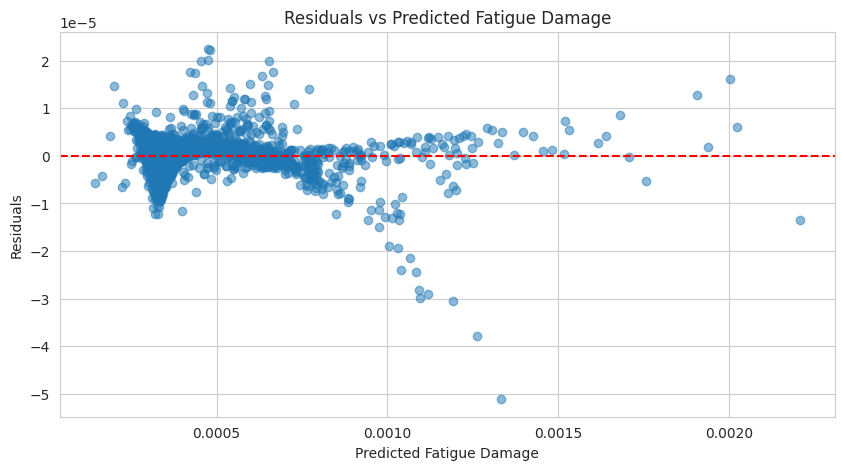

In [38]:
# Plot residuals against predicted fatigue damage
plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred_degree3,
    residuals,
    alpha=0.5
)

# Add a horizontal reference line at zero
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Fatigue Damage')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Fatigue Damage')

plt.show()

# **Residual Distribution**

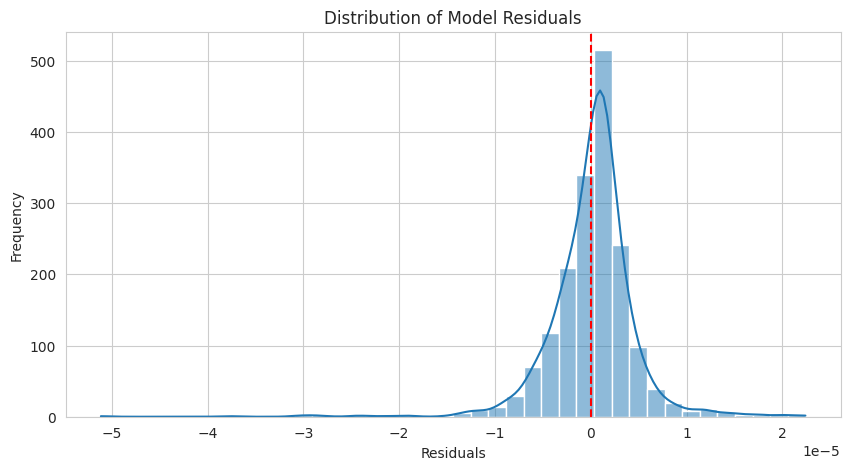

In [39]:
# Plot the distribution of residuals
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

# Add a vertical reference line at zero
plt.axvline(x=0, color='red', linestyle='--')

plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Model Residuals')

plt.show()

## **Metocean-Fatigue Relationship Analysis**

In this section, we will examine the statistical relationships between metocean conditions and estimated hourly fatigue damage.

We will use Pearson correlation to measure the strength and direction of linear relationships between the variables.

Correlation values range from -1 to +1:

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear relationship.

Correlation does not necessarily imply causation. Also, because our fatigue damage calculation uses an illustrative transfer function, these relationships describe the assumptions in our model rather than measured offshore fatigue behaviour.

In [40]:
# Select the metocean variables and fatigue damage
correlation_columns = [
    'hs_m',
    'tp_s',
    'current_ms',
    'wind_ms',
    'hourly_damage'
]

# Calculate Pearson correlation coefficients
correlation_matrix = fatigue_df[correlation_columns].corr()

# Display the correlation matrix
correlation_matrix

,hs_m,tp_s,current_ms,wind_ms,hourly_damage
hs_m,1.0000,-0.6522,0.5263,0.5728,0.8165
tp_s,-0.6522,1.0000,-0.5903,-0.6299,-0.2067
current_ms,0.5263,-0.5903,1.0000,0.4956,0.4591
wind_ms,0.5728,-0.6299,0.4956,1.0000,0.3650
hourly_damage,0.8165,-0.2067,0.4591,0.3650,1.0000


### **Correlation Heatmap**

We will use a heatmap to visualise the correlation coefficients.

The heatmap will help us identify which metocean variables have stronger positive or negative linear associations with hourly fatigue damage.

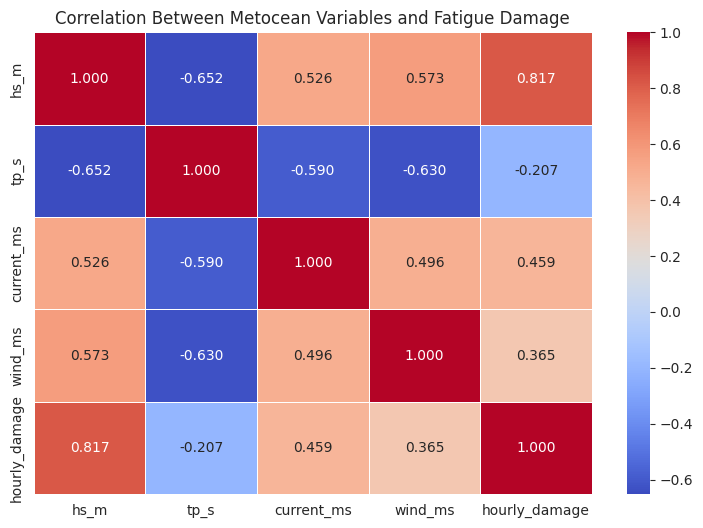

In [41]:
# Create a correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5
)

plt.title('Correlation Between Metocean Variables and Fatigue Damage')
plt.show()

## **Fatigue Monitoring Dashboard**

In this section, we will develop a dashboard to visualise the relationship between metocean conditions and estimated fatigue damage.

The dashboard will contain four components:

1. Monthly fatigue damage accumulation.
2. Significant wave height versus hourly fatigue damage.
3. Predicted versus actual fatigue damage.
4. Cumulative fatigue damage trajectory.

Before creating the visualisations, we will prepare the dataset by extracting the month and calculating monthly and cumulative fatigue damage.

These visualisations will help us examine how environmental conditions influence the estimated fatigue response and how damage accumulates over time.

In [42]:
# Create a copy of the fatigue dataset for dashboard analysis
dashboard_df = fatigue_df.copy()

# Convert timestamp to datetime format
dashboard_df['timestamp'] = pd.to_datetime(
    dashboard_df['timestamp']
)

# Extract month name and month number
dashboard_df['month'] = dashboard_df['timestamp'].dt.month_name()
dashboard_df['month_number'] = dashboard_df['timestamp'].dt.month

# Calculate cumulative fatigue damage
dashboard_df['cumulative_damage'] = (
    dashboard_df['hourly_damage'].cumsum()
)

# Display the first five observations
dashboard_df.head()

,timestamp,hs_m,tp_s,current_ms,wind_ms,hourly_damage,month,month_number,cumulative_damage
0,2025-01-01 00:00:00,1.5249,14.5806,0.6532,4.3755,0.0007,January,1,0.0007
1,2025-01-01 01:00:00,1.2600,14.2787,0.4710,6.4522,0.0003,January,1,0.0010
2,2025-01-01 02:00:00,1.2600,13.9385,0.5760,5.0083,0.0003,January,1,0.0013
3,2025-01-01 03:00:00,1.4542,14.1379,0.5640,3.9326,0.0005,January,1,0.0019
4,2025-01-01 04:00:00,1.3384,13.6802,0.6396,4.3208,0.0004,January,1,0.0023


### **Monthly Fatigue Damage Accumulation**

We will group the hourly fatigue damage values by month and calculate the total estimated damage accumulated during each month.

This will help identify which months contributed the most to the annual fatigue damage accumulation.

In [43]:
# Calculate total fatigue damage accumulated in each month
monthly_damage = (
    dashboard_df
    .groupby(['month_number', 'month'])['hourly_damage']
    .sum()
    .reset_index()
)

# Sort months chronologically
monthly_damage = monthly_damage.sort_values('month_number')

# Display monthly fatigue damage
monthly_damage

,month_number,month,hourly_damage
0,1,January,0.3305
1,2,February,0.2959
2,3,March,0.3285
3,4,April,0.5610
4,5,May,0.5773
5,6,June,0.5419
6,7,July,0.5662
7,8,August,0.5670
8,9,September,0.5503
9,10,October,0.5705


## **Monthly Fatigue Damage Visualisation**

We will create a bar chart showing the total estimated fatigue damage accumulated during each month of 2025.

The chart will help us identify periods of relatively high and low fatigue damage accumulation and examine possible seasonal patterns.

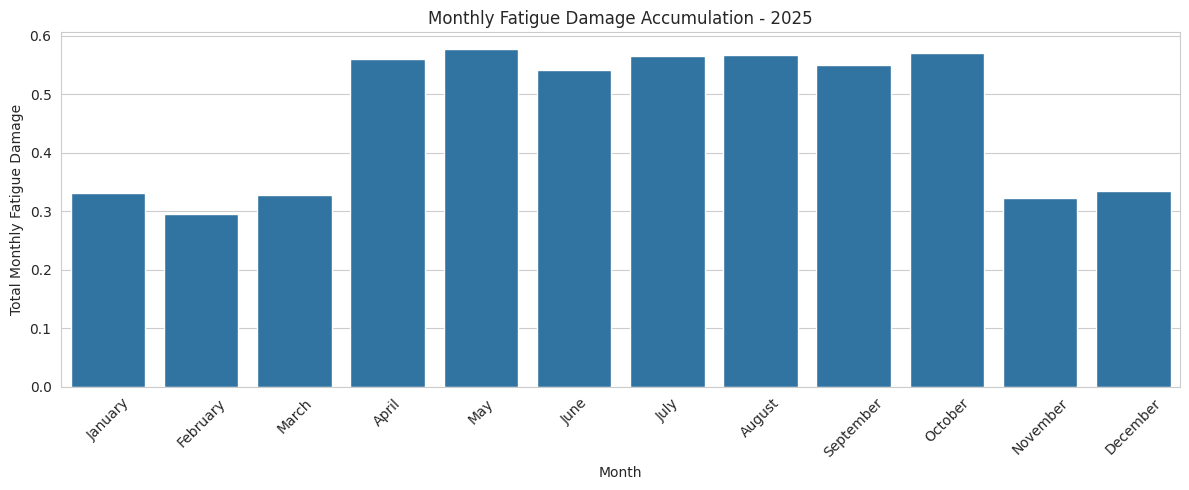

In [44]:
# Create a bar chart of monthly fatigue damage
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_damage,
    x='month',
    y='hourly_damage'
)

plt.xlabel('Month')
plt.ylabel('Total Monthly Fatigue Damage')
plt.title('Monthly Fatigue Damage Accumulation - 2025')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **Significant Wave Height vs Hourly Fatigue Damage**

In this section, we will investigate the relationship between significant wave height (Hs) and estimated hourly fatigue damage.

A scatter plot will be used to display individual hourly observations.

The plot will help us examine whether increasing significant wave height is associated with increasing fatigue damage and identify any unusual observations or variations in the relationship.

Since fatigue damage is also influenced by wave period and current speed, Hs alone may not explain all the variations in fatigue damage.

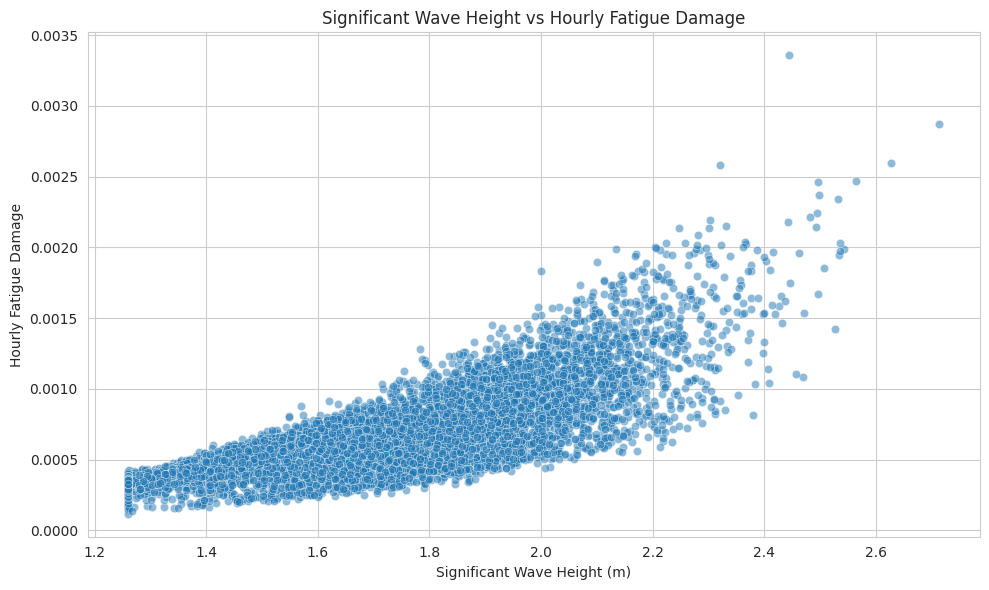

In [45]:
# Create a scatter plot of Hs against hourly fatigue damage
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=fatigue_df,
    x='hs_m',
    y='hourly_damage',
    alpha=0.5
)

plt.xlabel('Significant Wave Height (m)')
plt.ylabel('Hourly Fatigue Damage')
plt.title('Significant Wave Height vs Hourly Fatigue Damage')

plt.tight_layout()
plt.show()

## **Predicted vs Actual Fatigue Damage**

In this section, we will compare the fatigue damage predicted by the Degree 3 polynomial regression model with the actual fatigue damage values calculated from the spectral fatigue pipeline.

A scatter plot will be used to evaluate how closely the predictions agree with the actual values.

A reference line representing perfect prediction will be included.

Points close to this reference line indicate accurate predictions, while points farther away represent larger prediction errors.

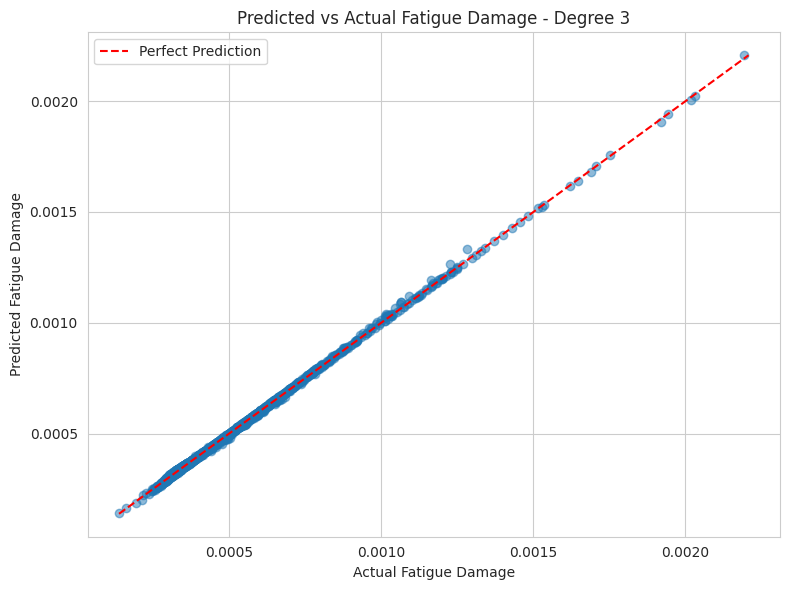

In [46]:
# Create a predicted vs actual scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_degree3,
    alpha=0.5
)

# Calculate plot limits for the reference line
plot_min = min(y_test.min(), y_pred_degree3.min())
plot_max = max(y_test.max(), y_pred_degree3.max())

# Add the perfect prediction reference line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Fatigue Damage')
plt.ylabel('Predicted Fatigue Damage')
plt.title('Predicted vs Actual Fatigue Damage - Degree 3')
plt.legend()

plt.tight_layout()
plt.show()

## **Cumulative Fatigue Damage Trajectory**

In this section, we will visualise the cumulative fatigue damage over the one-year observation period.

Cumulative fatigue damage is calculated by adding the hourly fatigue damage values sequentially throughout the year.

The resulting trajectory helps us understand how estimated fatigue damage builds up over time and identify periods of relatively rapid damage accumulation.

This analysis is based on the calculated hourly fatigue damage values and does not represent a validated remaining-life assessment of an actual offshore riser.

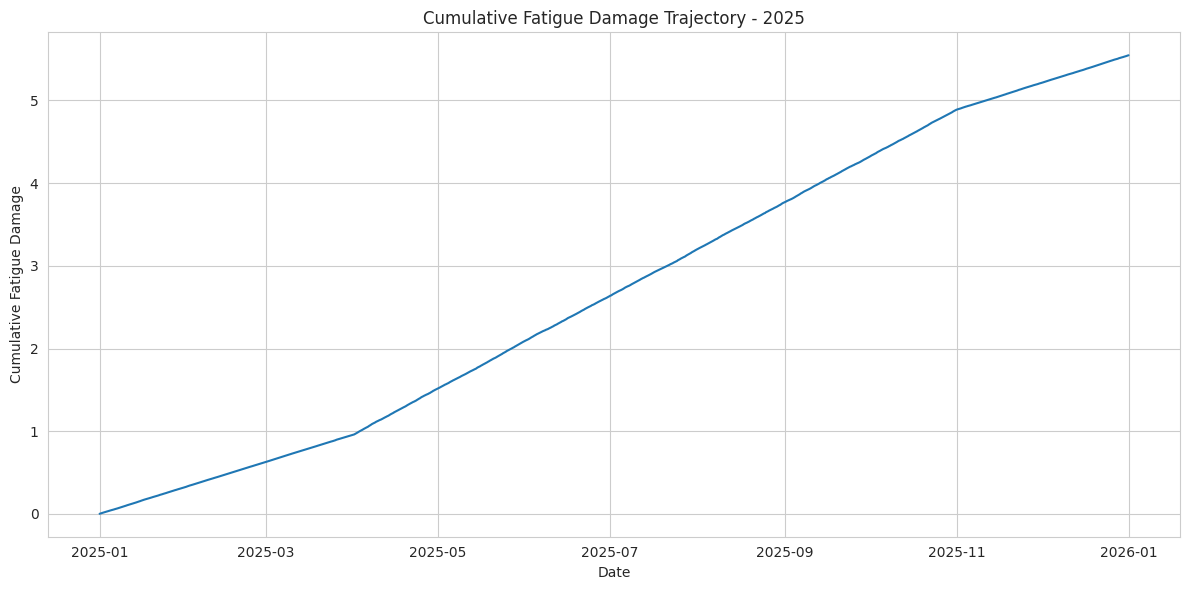

In [47]:
# Create a cumulative fatigue damage trajectory
plt.figure(figsize=(12, 6))

plt.plot(
    dashboard_df['timestamp'],
    dashboard_df['cumulative_damage']
)

plt.xlabel('Date')
plt.ylabel('Cumulative Fatigue Damage')
plt.title('Cumulative Fatigue Damage Trajectory - 2025')

plt.grid(True)
plt.tight_layout()
plt.show()

### **Total Annual Fatigue Damage**

We will calculate the total estimated fatigue damage accumulated over the entire observation period.

This value represents the sum of all 8,760 hourly fatigue damage estimates generated by our spectral fatigue pipeline.

In [48]:
# Calculate total annual fatigue damage
annual_damage = dashboard_df['hourly_damage'].sum()

# Display the result
print(f"Total Annual Fatigue Damage: {annual_damage:.4f}")

Total Annual Fatigue Damage: 5.5470


## **Export Fatigue Correlation Dataset**

The fatigue correlation dataset contains the hourly metocean observations and their corresponding estimated fatigue damage values.

We will export this dataset as a CSV file for further analysis, reporting and use in other applications.

The exported dataset will contain:

- Timestamp
- Significant wave height
- Peak wave period
- Current speed
- Wind speed
- Hourly fatigue damage

In [49]:
# Export the fatigue correlation dataset to CSV
fatigue_df.to_csv(
    'Jubilee_TRP3_Fatigue_Correlation_Dataset.csv',
    index=False
)
print("Fatigue correlation dataset exported successfully.")

Fatigue correlation dataset exported successfully.


##  **Model Performance Comparison**

Three polynomial regression models were developed to predict hourly fatigue damage from metocean variables.

The models were evaluated using:

1. Test R² and Mean Absolute Error (MAE).
2. Five-fold time-series cross-validation.
3. Residual analysis.

The polynomial degrees evaluated were 1, 2 and 3.

The objective was to identify the model that provides the best predictive performance and consistency.

In [50]:
# Create a consolidated model performance report
model_report = performance_df.merge(
    cv_results_df,
    on='Model'
)

# Display the consolidated results
model_report

,Model,R2,MAE,Mean R2,R2 Std,Mean MAE,MAE Std
0,Degree 1,0.8102,0.0001,0.8567,0.0602,0.0001,0.0000
1,Degree 2,0.9845,0.0000,0.9735,0.0350,0.0000,0.0000
2,Degree 3,0.9996,0.0000,0.9970,0.0054,0.0000,0.0000


### **Export Model Performance Report**

The consolidated model performance results will be exported as a CSV file for documentation and reporting.

In [52]:
# Export model performance results
model_report.to_csv(
    'Jubilee_TRP3_Model_Performance_Report.csv',
    index=False
)

print("Model performance report exported successfully.")

Model performance report exported successfully.


## **Final Project Quality Check**

Before completing the exercise, we will verify that the main analysis outputs have been generated successfully.

The checks will cover:

- Number of hourly observations in the fatigue correlation dataset.
- Presence of missing values.
- Presence of negative fatigue damage values.
- Total annual estimated fatigue damage.
- Availability of all three trained regression models.
- Availability of the exported model performance results.

This final check helps ensure that the analysis outputs are complete and internally consistent.

In [53]:
# Check fatigue correlation dataset
print("Fatigue Dataset Shape:", fatigue_df.shape)

print("\nMissing Values:")
print(fatigue_df.isnull().sum())

print("\nNegative Damage Values:",
      (fatigue_df['hourly_damage'] < 0).sum())

print("\nTotal Annual Damage:",
      fatigue_df['hourly_damage'].sum())

# Check trained models
print("\nTrained Models:")
for degree in models:
    print(f"Degree {degree}: Available")

# Check model performance report
print("\nModel Performance Report:")
print(model_report)

Fatigue Dataset Shape: (8760, 6)

Missing Values:
timestamp        0
hs_m             0
tp_s             0
current_ms       0
wind_ms          0
hourly_damage    0
dtype: int64

Negative Damage Values: 0

Total Annual Damage: 5.547031010764298

Trained Models:
Degree 1: Available
Degree 2: Available
Degree 3: Available

Model Performance Report:
      Model     R2    MAE  Mean R2  R2 Std  Mean MAE  MAE Std
0  Degree 1 0.8102 0.0001   0.8567  0.0602    0.0001   0.0000
1  Degree 2 0.9845 0.0000   0.9735  0.0350    0.0000   0.0000
2  Degree 3 0.9996 0.0000   0.9970  0.0054    0.0000   0.0000


### **Methodological Limitations and Engineering Considerations**

The fatigue correlation model was developed using a spectral fatigue calculation based on JONSWAP wave spectra, an illustrative wave-to-stress transfer function and a narrow-band fatigue damage approximation.

The following limitations should be considered:

1. The transfer function was developed using assumed coefficients because calibrated riser response data or an OrcaFlex-derived transfer function was not available.

2. The stress response and calculated fatigue damage therefore represent an illustrative computational workflow rather than validated structural response.

3. The S-N curve parameters and stress-unit conventions require verification against the applicable offshore fatigue design standard and material/environmental conditions.

4. The analysis covers one year of synthetic or supplied metocean observations. Longer observation periods would be required for stronger conclusions about long-term environmental variability.

5. The polynomial regression models learn the relationship embedded in the generated fatigue dataset. Their high predictive scores do not independently demonstrate real-world fatigue prediction capability.

6. Wind speed was included as a model predictor but was not directly incorporated into the spectral fatigue calculation. Its predictive contribution should therefore be examined critically.

Further engineering validation should use calibrated hydrodynamic and structural response models, appropriate fatigue design parameters and measured or validated environmental and structural response data.